# Step 2d: the three region formulas, paper Fig. 4(a)
Sheet density n (cm⁻²) against η_F: OFF Eq. (9), Middle Eq. (13), Deep ON Eq. (10) as printed and corrected,
against the exact (N_C·F½)^(2/3) [P, Eqs. (9), (10), (13); our corrections labelled].

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
from charge import NC2, sheet_exact, n_sub, n_mid, n_on, n_on_printed

# the paper's Fig. 4(a), read from the PDF [P]
paper = {}
for name in ["numerical", "off", "middle", "deep_on", "analytical"]:
    paper[name] = np.loadtxt(f"paper_data/fig4a_{name}.csv", delimiter=",", skiprows=3)

In [4]:
# theta1, theta2 are not given in the paper: fit Eq. (13) (printed prefactor kept) to the Fig. 4(a) Middle curve [CALIBRATE]
m = paper["middle"]
fit = least_squares(lambda th: np.log(n_mid(m[:, 0], th[0], th[1])) - np.log(m[:, 1]), [0.3, 0.0])
print(f"theta1 = {fit.x[0]:.3f}, theta2 = {fit.x[1]:.3f}, rms misfit = {100 * np.sqrt(np.mean(fit.fun**2)):.1f} %")

theta1 = 0.269, theta2 = 0.431, rms misfit = 1.8 %


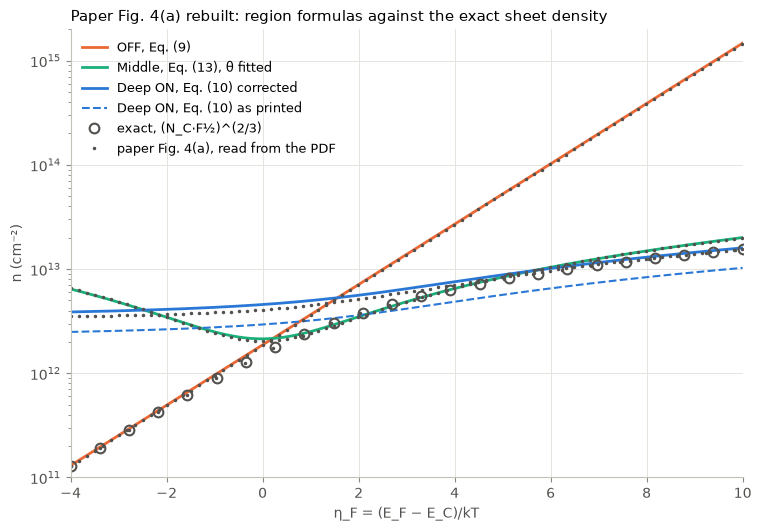

In [5]:
# our curves
eta = np.linspace(-4, 10, 701)                     # smooth lines
eta_pts = np.linspace(-4, 10, 24)                  # circles, like the paper's
n_exact = np.array([sheet_exact(e) for e in eta_pts])

# style
BLUE, ORANGE, AQUA, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#52514e", "#898781", "#e1e0d9"
plt.rcParams.update({"font.size": 10, "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK, "ytick.labelcolor": INK,
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False})
fig, ax = plt.subplots(figsize=(7.5, 5.2), constrained_layout=True)

# region formulas from charge.py
ax.semilogy(eta, n_sub(eta), color=ORANGE, lw=2, label="OFF, Eq. (9)")
ax.semilogy(eta, n_mid(eta), color=AQUA, lw=2, label="Middle, Eq. (13), θ fitted")
ax.semilogy(eta, n_on(eta), color=BLUE, lw=2, label="Deep ON, Eq. (10) corrected")
ax.semilogy(eta, n_on_printed(eta), color=BLUE, lw=1.5, ls="--", label="Deep ON, Eq. (10) as printed")

# the exact reference
ax.semilogy(eta_pts, n_exact, "o", mfc="none", mec=INK, ms=7, mew=1.5, label="exact, (N_C·F½)^(2/3)")

# the paper's own curves on top
for k in ["off", "middle", "deep_on"]:
    ax.semilogy(paper[k][::8, 0], paper[k][::8, 1], ".", color=INK, ms=3)
ax.semilogy(paper["numerical"][:, 0], paper["numerical"][:, 1], ".", color=INK, ms=3,
            label="paper Fig. 4(a), read from the PDF")

# axes, labels, save
ax.set_xlim(-4, 10); ax.set_ylim(1e11, 2e15)
ax.set_xlabel("η_F = (E_F − E_C)/kT"); ax.set_ylabel("n (cm⁻²)")
ax.set_title("Paper Fig. 4(a) rebuilt: region formulas against the exact sheet density", loc="left", fontsize=11)
ax.grid(True, color=GRID, lw=0.6); ax.legend(loc="upper left", fontsize=9)

fig.savefig("figures/step2d_fig4a.png", dpi=200)
plt.show()